# Taller Lagos y Ríos
## SWOT: el satélite que mide la **altura del agua** del lago Chinchaycocha

Landsat ve el **área** del lago. **SWOT** (NASA–CNES, lanzado en diciembre 2022) mide además el **nivel del agua** (WSE, *water surface elevation*) con un radar que **atraviesa las nubes**.

**Área + nivel =  cambio de volumen**


### Paso 0 · Instalar librerías (≈1 min)

In [ ]:
!pip install -q earthaccess geopandas

###  Paso 1 · Parámetros

In [ ]:
FECHA_INICIO = "2023-07-01"     # SWOT empezó su órbita científica en julio 2023
FECHA_FIN    = "2026-10-31"
MAX_ARCHIVOS = 800               # Modificado para procesar todas las pasadas (791 encontradas)

### ▶️ Paso 2 · Iniciar sesión en NASA Earthdata

In [ ]:
import earthaccess
auth = earthaccess.login()   # te pedirá usuario y contraseña de Earthdata

Enter your Earthdata Login username: merely_22
Enter your Earthdata password: ··········


### ▶️ Paso 3 · Buscar los datos SWOT del lago
Producto: **L2_HR_LakeSP – Prior**: una fila por lago y por pasada del satélite, con nivel (`wse`) y área (`area_total`).

In [ ]:
caja = (-76.30, -11.25, -75.90, -10.80)    # (lon mín, lat mín, lon máx, lat máx)

resultados = []
for producto in ["SWOT_L2_HR_LakeSP_D", "SWOT_L2_HR_LakeSP_2.0"]:   # versión nueva y, si no hay, la anterior
    resultados = earthaccess.search_data(short_name=producto, bounding_box=caja,
                                         temporal=(FECHA_INICIO, FECHA_FIN), granule_name="*Prior*")
    if len(resultados) > 0:
        print(f"Producto usado: {producto}")
        break

print("Pasadas encontradas:", len(resultados))
resultados = resultados[:MAX_ARCHIVOS]
print("Vamos a descargar:", len(resultados))

Producto usado: SWOT_L2_HR_LakeSP_D
Pasadas encontradas: 791
Vamos a descargar: 791


### ▶️ Paso 4 · Descargar y leer solo el lago Chinchaycocha

In [ ]:
import geopandas as gpd, pandas as pd, os
from shapely.geometry import Point

punto_lago = Point(-76.10, -11.02)       # centro del lago
archivos = earthaccess.download(resultados, "swot_datos")

filas = []
for z in archivos:
    try:
        g = gpd.read_file(f"zip://{z}")
    except Exception as e:
        print("No se pudo leer", os.path.basename(str(z)), e); continue
    g = g[g.geometry.notna()]
    g = g[g.intersects(punto_lago)]
    for _, r in g.iterrows():
        filas.append({"fecha": r.get("time_str"), "lake_id": r.get("lake_id"),
                      "nivel_m": r.get("wse"), "area_km2": r.get("area_total")})
    os.remove(z)                          # liberamos espacio en Colab

swot = pd.DataFrame(filas)
swot = swot[(swot["nivel_m"] > 3000) & (swot["nivel_m"] < 5000)]     # quitamos valores vacíos (-999999…)
swot["fecha"] = pd.to_datetime(swot["fecha"], errors="coerce")
swot = swot.dropna(subset=["fecha"]).sort_values("fecha").reset_index(drop=True)
swot

QUEUEING TASKS | :   0%|          | 0/791 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/791 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/791 [00:00<?, ?it/s]

,fecha,lake_id,nivel_m,area_km2
0,2023-07-26 22:22:46+00:00,6220076913,4083.753,189.239343
1,2023-09-06 15:52:58+00:00,6220076913,4083.402,174.575672
2,2023-09-27 12:38:02+00:00,6220076913,4081.781,172.755554
3,2023-10-18 09:23:05+00:00,6220076913,4083.021,171.198314
4,2023-11-08 06:08:11+00:00,6220076913,4082.775,167.449134
5,2023-12-19 23:38:20+00:00,6220076913,4084.304,172.910582
6,2024-01-09 20:23:25+00:00,6220076913,4083.275,198.413234
7,2024-01-30 17:08:32+00:00,6220076913,4083.687,208.172668
8,2024-02-20 13:53:37+00:00,6220076913,4084.077,233.486684
9,2024-03-12 10:38:39+00:00,6220076913,4084.526,245.963819


### Paso 5 · Gráficos: nivel y área del lago según SWOT

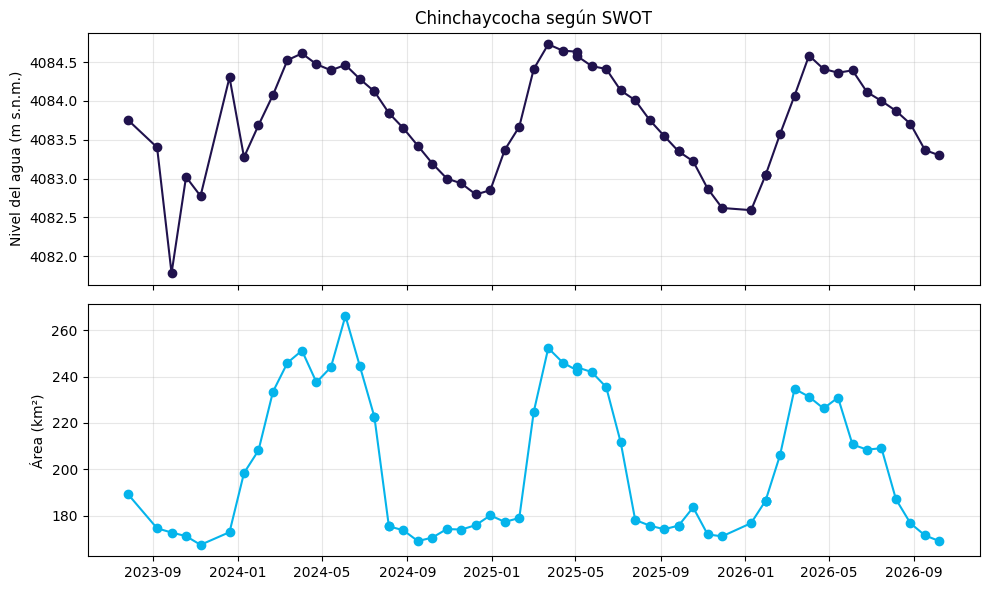

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(swot["fecha"], swot["nivel_m"], "o-", color="#20124D")
ax[0].set_ylabel("Nivel del agua (m s.n.m.)"); ax[0].set_title("Nivel y área de la Laguna Chinchaycocha - Huancavelica "); ax[0].grid(alpha=0.3)
ax[1].plot(swot["fecha"], swot["area_km2"], "o-", color="#05B4EB")
ax[1].set_ylabel("Área (km²)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [ ]:
print(f"Nivel máximo: {swot.nivel_m.max():.2f} m  ({swot.loc[swot.nivel_m.idxmax(), 'fecha']:%Y-%m-%d})")
print(f"Nivel mínimo: {swot.nivel_m.min():.2f} m  ({swot.loc[swot.nivel_m.idxmin(), 'fecha']:%Y-%m-%d})")
print(f"Variación de nivel: {swot.nivel_m.max() - swot.nivel_m.min():.2f} m")

Nivel máximo: 4084.73 m  (2025-03-23)
Nivel mínimo: 4081.78 m  (2023-09-27)
Variación de nivel: 2.95 m


### ▶️ Paso 6 · Del nivel al volumen (idea de Frappart, Visitación *et al.*, 2024)
Si el nivel baja **Δh** metros sobre un lago de área **A**, el volumen cambia aproximadamente:

**ΔV ≈ A × Δh**

In [ ]:
A_media_m2 = swot["area_km2"].median() * 1e6
dh = swot["nivel_m"].max() - swot["nivel_m"].min()
dV_hm3 = A_media_m2 * dh / 1e6        # 1 hm³ = 1 millón de m³
print(f"Cambio de volumen aproximado: {dV_hm3:.0f} hm³ (millones de m³)")
print(f"≈ {dV_hm3 * 1e6 / 2500:,.0f} piscinas olímpicas")

Cambio de volumen aproximado: 550 hm³ (millones de m³)
≈ 219,976 piscinas olímpicas


### 🧠 Paso 7 · Para pensar
1. ¿En qué meses el nivel es más bajo? ¿Coincide con la época seca (may–oct)?
2. ¿El nivel de 2026 es más bajo que el de 2024 en la misma temporada?
3. ¿Por qué SWOT puede ver el lago en meses de lluvia y Landsat casi no?
4. El lago está **regulado** por la represa de Upamayo: ¿cómo separarías el efecto del clima del efecto de la operación?

In [ ]:
swot.to_csv("Chinchaycocha_SWOT.csv", index=False)
from google.colab import files
files.download("Chinchaycocha_SWOT.csv")